[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kudinha/MW1-Rotation-C-D/blob/main/Fuel_Cell_Analysis_Corrected_With_Colab_Badge.ipynb)

# Hydrogen, Ethanol, and Mixed Fuel Cell Analysis

**Updated power-density figures.** The original data loading, equations, parameter fits, and confidence interval calculations are retained. Power-density panels are grouped into **hydrogen (3)**, **ethanol (5)**, and **mixed fuel cells (2)**. Ethanol and mixed-fuel conditions also have separate comparison/overlay plots.

*Run this notebook in Google Colab with access to the Google Sheets `Hydrogen Experiments` and `Et-Fuel cell`.*

In [ ]:
from google.colab import drive
drive.mount('/content/drive')   # click through the authorization prompt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import t

AREA = 1.0   # cm^2, active membrane area -- REPLACE with your cell's area

Mounted at /content/drive


Load data

In [ ]:
# A native Google Sheet isn't an .xlsx file on Drive, so read it with gspread.
import gspread
from google.colab import auth
from google.auth import default

auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

SHEET_NAME = "Hydrogen Experiments"   # the Google Sheet's title as shown in Drive
book = gc.open(SHEET_NAME)         # or: gc.open_by_url("https://docs.google.com/...")

def load_sheet(tab):
    rows = book.worksheet(tab).get_all_values()[1:]   # skip the header row
    V, I = [], []
    for r in rows:
        # Column B = V (V), column C = I (mA); column A (R) is ignored
        if len(r) > 2 and r[1] != "" and r[2] != "":
            V.append(float(r[1]))
            I.append(float(r[2]))
    V = np.array(V) * 1000.0   # V -> mV
    i = np.array(I) / AREA     # mA -> mA/cm^2
    order = np.argsort(i)
    return i[order], V[order]

# (label, tab name) -- tab names must match exactly
datasets = []
for name, tab in [("PEM", "PEM Fuel Cell"), ("Series", "Series"), ("Parallel", "Parallel")]:
    i, V = load_sheet(tab)
    datasets.append((name, i, V))
    print(f"{name}: {len(i)} points")

PEM: 36 points
Series: 24 points
Parallel: 38 points


Model

### ✏️ MODIFIED — E and A are now separate (lab manual equation)

Before, the model combined E and A into one constant, C = E + A. Now it uses the lab manual's equation directly:

$$V = E - (B\log|i| - A) - iR - w\,e^{z i}$$

- **E** (reversible cell potential) comes from thermodynamics, so it is **fixed from the prelab, not fitted**. See the next cell.
- **A** (Tafel offset) is **fitted**, with the constraint **A ≤ 0**. Because the activation loss is $B\log(i/i_0)$, A = B·log₁₀(i₀), and the exchange current density i₀ is far below 1 mA/cm².

**Why E isn't fitted:** E and A only ever appear as the sum E + A, so the data cannot tell them apart. Any pair with the same sum gives exactly the same curve. Fitting both would give huge errors for both. Fixing E from the prelab and fitting A is how they are constrained independently.

In [ ]:
# >>> MODIFIED (E/A split): the lab manual's equation, with E and A kept separate.
def model(i, E, A, B, R, w, z):
    # V = E - (B*log10(i) - A) - i*R - w*exp(z*i)
    # E [mV]  reversible cell potential -- fixed from the prelab, NOT fitted
    # A [mV]  Tafel offset, A = B*log10(i0) -- fitted, A <= 0 because i0 < 1 mA/cm^2
    # B [mV/decade], R [mV*cm^2/mA = ohm*cm^2], w [mV], z [cm^2/mA]
    return E - (B*np.log10(i) - A) - i*R - w*np.exp(z*i)

### 🆕 ADDED — Reversible potential E for each condition (prelab)

| Condition | E (mV) | Why |
|---|---|---|
| Hydrogen single cell (PEM) and parallel | 1229 | H₂ + ½O₂ → H₂O has one product, so E is a single value |
| Hydrogen series | 2 × 1229 = 2458 | voltages add in series |
| Ethanol single cell (5, 10, 13 vol%) and parallel | 1166.33 – 1421 | prelab range: oxidation to CO₂ (1166.33) or to acetic acid (1421) |
| Ethanol series | 2 × (1166.33 – 1421) = 2332.66 – 2842 | voltages add in series |
| H+Et series | 1229 + (1166.33 – 1421) = 2395.33 – 2650 | one hydrogen cell + one ethanol cell |
| H+Et parallel | 1166.33 – 1421 | the shared voltage must lie between the two cells' E values; this range spans both (it includes 1229) |

**How the range is used:** each fit is done at the **lower** E. Because E and A only appear as E + A, the upper E gives exactly the same curve and the same B, R, w and z; only A shifts by (E_high − E_low). The printout gives A at both ends of the range, and i₀ = 10^(A/B).

In [ ]:
# ===================== ADDED: reversible potential E from the prelab [mV] =====================
E_H2 = 1229.0                    # H2 + 1/2 O2 -> H2O
E_ETOH = (1166.33, 1421.0)       # ethanol -> CO2  /  ethanol -> acetic acid

E_RANGE = {   # (lowest E, highest E) for each condition
    # hydrogen
    "PEM":      (E_H2, E_H2),
    "Series":   (2 * E_H2, 2 * E_H2),
    "Parallel": (E_H2, E_H2),
    # ethanol
    "5 vol%":             E_ETOH,
    "10 vol%":            E_ETOH,
    "13 vol%":            E_ETOH,
    "Series (10 vol%)":   (2 * E_ETOH[0], 2 * E_ETOH[1]),
    "Parallel (10 vol%)": E_ETOH,
    # mixed hydrogen + ethanol
    "H+Et series":   (E_H2 + E_ETOH[0], E_H2 + E_ETOH[1]),
    "H+Et parallel": E_ETOH,   # shared voltage lies between 1166.33 and 1421 (includes 1229)
}

def E_fit(name):
    """E used in the fit (lowest value of the range). Conditions not listed are treated as ethanol single cells."""
    return E_RANGE.get(name, E_ETOH)[0]

def with_fixed_E(p, cov, E):
    """Add the fixed E back in front of the fitted (A, B, R, w, z): 6 parameters, E has zero variance."""
    p6 = np.insert(np.asarray(p, dtype=float), 0, E)
    cov6 = np.zeros((6, 6))
    cov6[1:, 1:] = cov
    return p6, cov6

Parameter scales

In [ ]:
# With w = 0, eqn [15] is linear in (E + A), B, R,   # >>> MODIFIED: label only so it can be fit by least squares,
# the multi-variable version of LINEST / np.polyfit from the module.
def linear_scale_fit(i, V):
    X = np.column_stack([np.ones_like(i), -np.log10(i), -i])  # design matrix
    p, *_ = np.linalg.lstsq(X, V, rcond=None)
    resid = V - X @ p
    dof = len(V) - X.shape[1]
    cov = (resid @ resid / dof) * np.linalg.inv(X.T @ X)       # same as polyfit cov=True
    return p, np.sqrt(np.diag(cov))

for name, i, V in datasets:
    p, s = linear_scale_fit(i, V)
    print(f"{name}: E + A = {p[0]:.0f} ± {s[0]:.0f} mV, "
          f"B = {p[1]:.1f} ± {s[1]:.1f} mV/dec, R = {p[2]:.2f} ± {s[2]:.2f}")

PEM: E + A = 858 ± 1 mV, B = 93.8 ± 4.0 mV/dec, R = 2.53 ± 0.19
Series: E + A = 1708 ± 17 mV, B = 205.5 ± 22.8 mV/dec, R = 2.45 ± 0.41
Parallel: E + A = 892 ± 1 mV, B = 55.6 ± 1.6 mV/dec, R = 2.57 ± 0.18


nonlinear fit of eq 15

### ✏️ MODIFIED — hydrogen 5-parameter fit (E fixed, A fitted)

This is the same unconstrained fit as before, except that A is fitted in place of C, with E fixed at 1229 mV (or 2458 mV for series). The curve is identical to the old fit; A is just the old C minus E.

In [ ]:
# >>> MODIFIED (E/A split): E is fixed from the prelab; A replaces C as the fitted offset.
def full_fit(i, V, E):
    p_lin, _ = linear_scale_fit(i, V)                     # p_lin[0] = E + A
    f = lambda i, A, B, R, w, z: model(i, E, A, B, R, w, z)
    p0 = [p_lin[0] - E, max(p_lin[1], 1e-3), max(p_lin[2], 1e-3), 1.0, 0.03]  # start from Step 1
    lower = [-E, 0, 0, 0, 0]                              # same limits as before: 0 <= E + A <= 5000
    upper = [5000 - E, 1000, 100, 1e4, 1.0]
    p, cov = curve_fit(f, i, V, p0=p0, bounds=(lower, upper), maxfev=200000)
    p, cov = with_fixed_E(p, cov, E)                      # back to all 6 parameters
    resid = V - model(i, *p)
    r2 = 1 - np.sum(resid**2) / np.sum((V - V.mean())**2)
    return p, cov, r2

fits = {}
names = ["E", "A", "B", "R", "w", "z"]
for name, i, V in datasets:
    p, cov, r2 = full_fit(i, V, E_fit(name))
    fits[name] = (p, cov)
    print(f"--- {name}  (R^2 = {r2:.4f})")
    for n, val, sd in zip(names, p, np.sqrt(np.diag(cov))):
        if n == "E":
            print(f"  E = {val:.6g} (fixed, prelab)")
        else:
            print(f"  {n} = {val:.4g} ± {sd:.2g}")   # sqrt of variance = stdev

--- PEM  (R^2 = 0.9929)
  E = 1229 (fixed, prelab)
  A = -371.2 ± 5.2e+05
  B = 93.76 ± 4.3
  R = 2.53 ± 2.4e+03
  w = 0.00475 ± 5.2e+05
  z = 5.96e-07 ± 5.1e+05
--- Series  (R^2 = 0.9677)
  E = 2458 (fixed, prelab)
  A = -750.2 ± 1.4e+06
  B = 205.5 ± 44
  R = 2.45 ± 2.8e+03
  w = 0.07376 ± 1.4e+06
  z = 3.766e-06 ± 3.8e+04
--- Parallel  (R^2 = 0.9956)
  E = 1229 (fixed, prelab)
  A = -337.4 ± 1.9e+05
  B = 55.57 ± 1.7
  R = 2.574 ± 19
  w = 0.0001115 ± 1.9e+05
  z = 1.103e-06 ± 1.7e+05


## 🆕 ADDED — Constrained fits (professor's rule) — updated for the E/A split

**Rule:** if a parameter's standard error is larger than its value, the data cannot determine it, so that term is removed (set to 0) and the fit is redone. The other parameters usually become well determined once the extra term is gone.

**Which term can be removed:** A (Tafel offset), B (activation loss) and R (resistance) are present in every real cell, so only the mass-transport term $w\,e^{zi}$ can physically be absent. Removing it means $w = 0$; once $w = 0$, $z$ has no effect on the curve, so it is set to 0 too.

**Check:** each constrained fit prints R² before and after, flags any parameter whose error is still larger than its value, and runs an F-test asking whether the $w\,e^{zi}$ term is actually needed (p < 0.05 means the data need it).

The cell below only defines helper functions. The constraints themselves are applied in the next cell (hydrogen) and after the ethanol fitting cell (ethanol).

In [ ]:
# ===================== ADDED: helper functions for constrained fits =====================
# (updated for the E/A split: E is always fixed, A is fitted with A <= 0)
from scipy.stats import f as f_dist

PARAM_NAMES = ["E", "A", "B", "R", "w", "z"]

def constrained_fit(i, V, fixed):
    """Fit the model holding the parameters in `fixed` constant. `fixed` must include E,
    e.g. fixed={"E": 1166.33, "w": 0, "z": 0}.
    Returns the full 6-parameter vector, its 6x6 covariance (0 for fixed ones), and the SSE."""
    E = fixed["E"]
    lower = np.array([0, -E, 0, 0, 0, 0], dtype=float)           # E + A >= 0
    upper = np.array([5000, 0, 1000, 200, 1000, 5.0], dtype=float)  # A <= 0 (i0 < 1 mA/cm²); z cap 5
    free = [k for k, n in enumerate(PARAM_NAMES) if n not in fixed]

    def f(i, *free_vals):
        full = [fixed.get(n, 0.0) for n in PARAM_NAMES]
        for k, v in zip(free, free_vals):
            full[k] = v
        return model(i, *full)

    # Try a few starting values for w (only matters when w is free); keep the best fit.
    starts = [1e-6, 0.05, 1.0] if "w" not in fixed else [0.0]
    best = None
    for w0 in starts:
        p0 = np.array([E, V.max() - E, 150, 20, w0, 1.0])[free]
        p0 = np.clip(p0, lower[free] + 1e-7, upper[free] - 1e-7)
        try:
            p, cov = curve_fit(f, i, V, p0=p0, bounds=(lower[free], upper[free]), maxfev=60000)
        except (RuntimeError, ValueError, FloatingPointError):
            continue
        sse = float(np.sum((V - f(i, *p)) ** 2))
        if best is None or sse < best[0]:
            best = (sse, p, cov)
    if best is None:
        raise RuntimeError(f"Constrained fit did not converge (fixed = {fixed}).")
    sse, p, cov = best

    p_full = np.array([fixed.get(n, 0.0) for n in PARAM_NAMES], dtype=float)
    p_full[free] = p
    cov_full = np.zeros((6, 6))
    cov_full[np.ix_(free, free)] = cov
    return p_full, cov_full, sse

def f_test(sse_full, sse_reduced, n, dropped=2):
    """F-test: does the w*exp(z*i) term (2 parameters) improve the fit more than noise would?
    The full model has 5 fitted parameters (A, B, R, w, z)."""
    F = max(sse_reduced - sse_full, 0) / dropped / (sse_full / (n - 5))
    return F, f_dist.sf(F, dropped, n - 5)

def run_constrained(name, i, V, fixed, sse_original, r2_original, note=""):
    """Refit with constraints (E fixed at the low end of its prelab range), print a short
    report, and return (params, cov, R², fixed incl. E)."""
    E_low, E_high = E_RANGE.get(name, E_ETOH)
    fixed = {"E": E_low, **fixed}
    sst = np.sum((V - V.mean()) ** 2)
    p, cov, sse = constrained_fit(i, V, fixed)
    r2 = 1 - sse / sst
    sds = np.sqrt(np.maximum(np.diag(cov), 0))

    # F-test for the mass-transport term (reuse this fit if it already has w = 0)
    w_removed = fixed.get("w", None) == 0
    sse_no_w = sse if w_removed else constrained_fit(i, V, {"E": E_low, "w": 0.0, "z": 0.0})[2]
    F, pval = f_test(sse_original, sse_no_w, len(i))

    print(f"--- {name}: R² = {r2_original:.4f} (all free)  ->  {r2:.4f} (constrained)")
    others = {k: v for k, v in fixed.items() if k != "E"}
    print("  fixed:", ", ".join(f"{k} = {v:g}" for k, v in others.items()) if others else "nothing (besides E)")

    # E and A: A at the low and high end of the E range (same curve, A shifts by E_high - E_low)
    A_low, sA = p[1], sds[1]
    A_high = A_low - (E_high - E_low)
    flag = "   <-- error still > value" if sA > abs(A_low) else ""
    if E_high == E_low:
        print(f"  E = {E_low:.6g} mV (fixed, prelab)  ->  A = {A_low:.4g} ± {sA:.2g} mV{flag}")
    else:
        print(f"  E = {E_low:.6g} to {E_high:.6g} mV (fixed, prelab range)  ->  "
              f"A = {A_low:.4g} to {A_high:.4g} ± {sA:.2g} mV{flag}")
    B_fit = p[2]
    if B_fit > 0:
        i0 = [10 ** (A_low / B_fit), 10 ** (A_high / B_fit)]
        rng = f"{i0[0]:.2g}" if E_high == E_low else f"{i0[0]:.2g} to {i0[1]:.2g}"
        print(f"  i0 = 10^(A/B) = {rng} mA/cm²")
    else:
        print("  i0 not defined (B = 0)")

    for n, v, s in zip(PARAM_NAMES, p, sds):
        if n not in fixed and n != "A":
            flag = "   <-- error still > value" if s > abs(v) else ""
            print(f"  {n} = {v:.4g} ± {s:.2g}{flag}")
    verdict = "term needed" if pval < 0.05 else "term not needed"
    print(f"  F-test for the w·e^(zi) term: F = {F:.2f}, p = {pval:.3g}  ({verdict})")
    if w_removed and pval < 0.05:
        print("  WARNING: w was set to 0 but the F-test says the data need this term. Revisit this constraint.")
    if note:
        print("  note:", note)
    return p, cov, r2, fixed

### 🆕 ADDED — Hydrogen: constrained fits

In the original hydrogen fits above, $z \approx 10^{-6}$ for all three configurations, so $w\,e^{zi} \approx w$ is just a constant that competes with A. That is why A, R, w and z all have errors far larger than their values (only B is well determined). Setting $w = z = 0$ removes the duplicate term. The result should match the "Parameter scales" (w = 0) fit, with A = (E + A from that fit) − E.

**The plots below now use these constrained fits.**

In [ ]:
# ===================== ADDED: hydrogen constrained fits =====================
# E is added automatically from E_RANGE (1229 mV, or 2458 mV for series).
H2_CONSTRAINTS = {
    "PEM":      {"w": 0.0, "z": 0.0},
    "Series":   {"w": 0.0, "z": 0.0},
    "Parallel": {"w": 0.0, "z": 0.0},
}
H2_NOTE = "z ≈ 0 in the original fit, so w·e^(zi) ≈ w duplicated A; A, R, w, z all had error > value."

for name, i, V in datasets:
    _, _, r2_original = full_fit(i, V, E_fit(name))           # original fit, for comparison
    sse_original = (1 - r2_original) * np.sum((V - V.mean()) ** 2)
    p, cov, r2, _ = run_constrained(name, i, V, H2_CONSTRAINTS.get(name, {}),
                                    sse_original, r2_original, H2_NOTE)
    fits[name] = (p, cov)                                      # plots below use this fit

--- PEM: R² = 0.9929 (all free)  ->  0.9929 (constrained)
  fixed: w = 0, z = 0
  E = 1229 mV (fixed, prelab)  ->  A = -371.2 ± 1.4 mV
  i0 = 10^(A/B) = 0.00011 mA/cm²
  B = 93.76 ± 4
  R = 2.53 ± 0.19
  F-test for the w·e^(zi) term: F = 0.00, p = 1  (term not needed)
  note: z ≈ 0 in the original fit, so w·e^(zi) ≈ w duplicated A; A, R, w, z all had error > value.
--- Series: R² = 0.9677 (all free)  ->  0.9677 (constrained)
  fixed: w = 0, z = 0
  E = 2458 mV (fixed, prelab)  ->  A = -750.3 ± 17 mV
  i0 = 10^(A/B) = 0.00022 mA/cm²
  B = 205.5 ± 23
  R = 2.45 ± 0.41
  F-test for the w·e^(zi) term: F = 0.00, p = 1  (term not needed)
  note: z ≈ 0 in the original fit, so w·e^(zi) ≈ w duplicated A; A, R, w, z all had error > value.
--- Parallel: R² = 0.9956 (all free)  ->  0.9956 (constrained)
  fixed: w = 0, z = 0
  E = 1229 mV (fixed, prelab)  ->  A = -337.4 ± 0.59 mV
  i0 = 10^(A/B) = 8.5e-07 mA/cm²
  B = 55.57 ± 1.6
  R = 2.574 ± 0.18
  F-test for the w·e^(zi) term: F = 0.00, p = 1  (

performance curve with 95% band

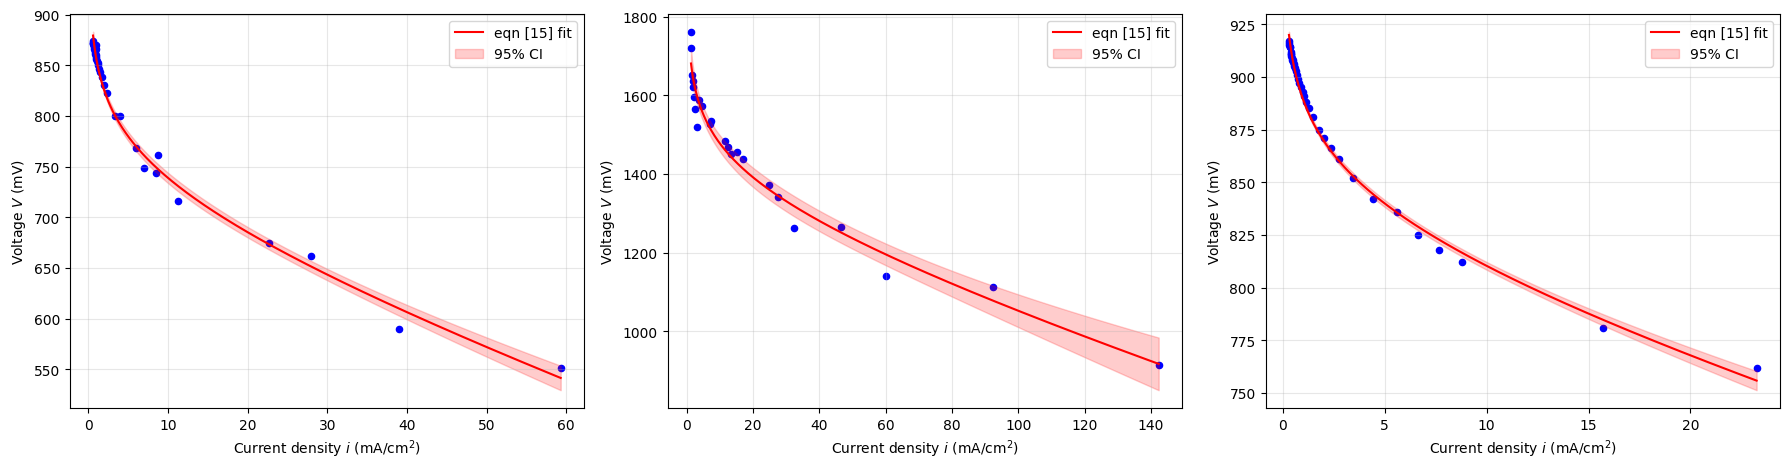

In [ ]:
def conf_band(i_fit, p, cov, n_data, level=0.95):
    # Delta method: propagate the parameter covariance through the model.
    # This is the nonlinear analog of the module's confidence-band formula.
    eps = 1e-6
    J = np.array([(model(i_fit, *(p + eps*np.eye(len(p))[k])) - model(i_fit, *p)) / eps
                  for k in range(len(p))]).T
    se = np.sqrt(np.einsum("ij,jk,ik->i", J, cov, J))
    n_fitted = np.count_nonzero(np.diag(cov) > 0)   # >>> MODIFIED: count only fitted (not fixed) parameters
    return t.ppf(0.5 + level/2, n_data - n_fitted) * se   # t-score instead of 1.96 (small n)

fig, axes = plt.subplots(1, len(datasets), figsize=(6 * len(datasets), 4.8))
for ax, (name, i, V) in zip(axes, datasets):
    p, cov = fits[name]
    i_fit = np.linspace(i.min(), i.max(), 400)
    V_fit = model(i_fit, *p)
    band = conf_band(i_fit, p, cov, len(i))

    ax.scatter(i, V, color="b", s=20, label="_nolegend_")
    ax.plot(i_fit, V_fit, "r-", label="eqn [15] fit")
    ax.fill_between(i_fit, V_fit - band, V_fit + band, color="r", alpha=0.2, label="95% CI")
    ax.set_xlabel(r"Current density $i$ (mA/cm$^2$)")
    ax.set_ylabel(r"Voltage $V$ (mV)")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

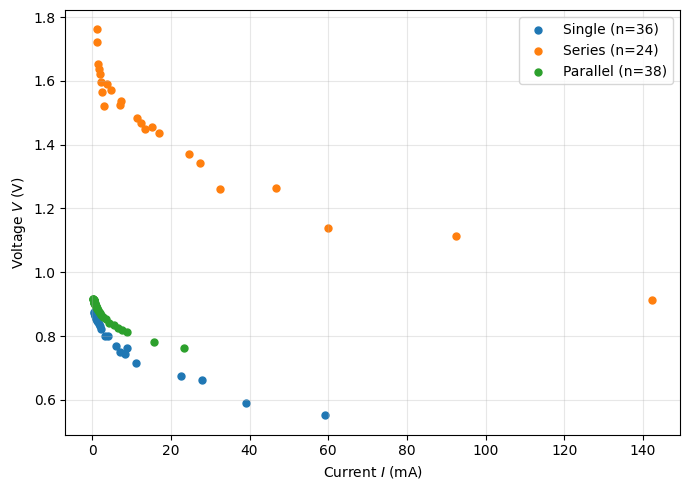

In [ ]:
# Scatter: V vs I for single, series, and parallel (Google Sheet "Hydrogen Experiments")
h2_book = gc.open("Hydrogen Experiments")   # the Sheet's title as shown in Drive

def load_tab(tab):
    rows = h2_book.worksheet(tab).get_all_values()[1:]   # skip header row
    V, I = [], []
    for r in rows:
        # Column B = V (V), column C = I (mA); column A (R) ignored
        if len(r) > 2 and r[1] != "" and r[2] != "":
            V.append(float(r[1]))
            I.append(float(r[2]))
    return np.array(I), np.array(V)

configs = [("Single", "PEM Fuel Cell", "tab:blue"),
           ("Series", "Series", "tab:orange"),
           ("Parallel", "Parallel", "tab:green")]

fig, ax = plt.subplots(figsize=(7, 5))
for label, tab, color in configs:
    I, V = load_tab(tab)
    ax.scatter(I, V, s=25, color=color, label=f"{label} (n={len(I)})")

ax.set_xlabel(r"Current $I$ (mA)")
ax.set_ylabel(r"Voltage $V$ (V)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Hydrogen: three power-density panels (PEM, series, parallel) and comparison plot

PEM: p_max = 3.211e-02 W/cm^2 at i = 59.30 mA/cm^2, V = 542 mV
Series: p_max = 1.304e-01 W/cm^2 at i = 142.30 mA/cm^2, V = 917 mV
Parallel: p_max = 1.757e-02 W/cm^2 at i = 23.25 mA/cm^2, V = 756 mV


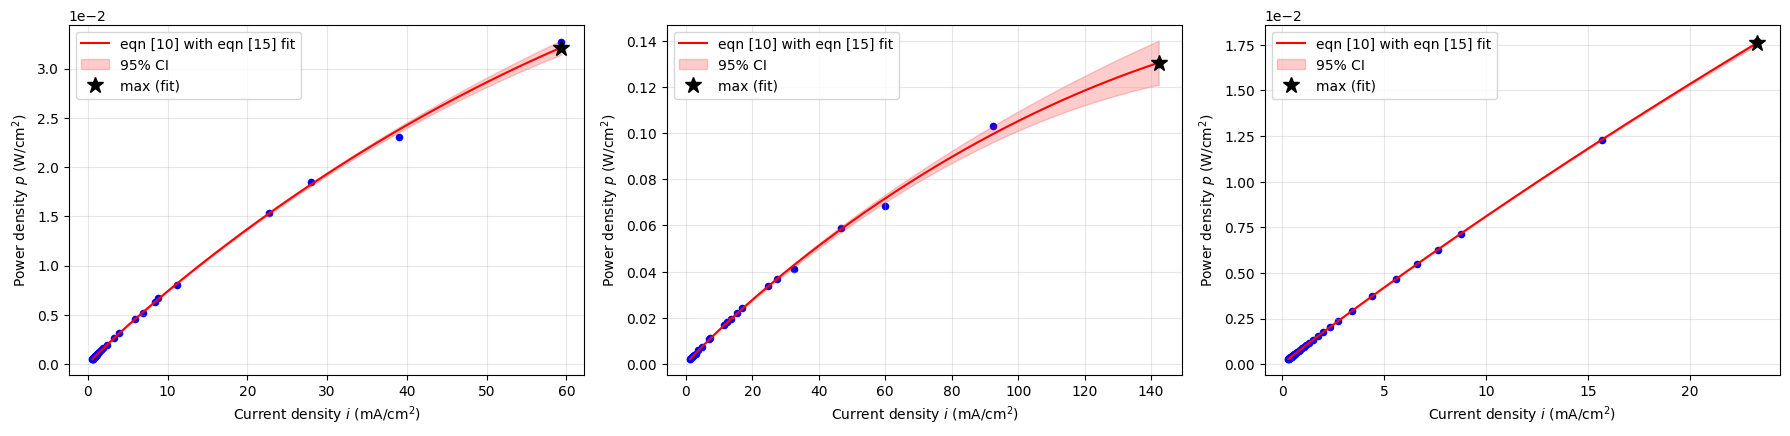

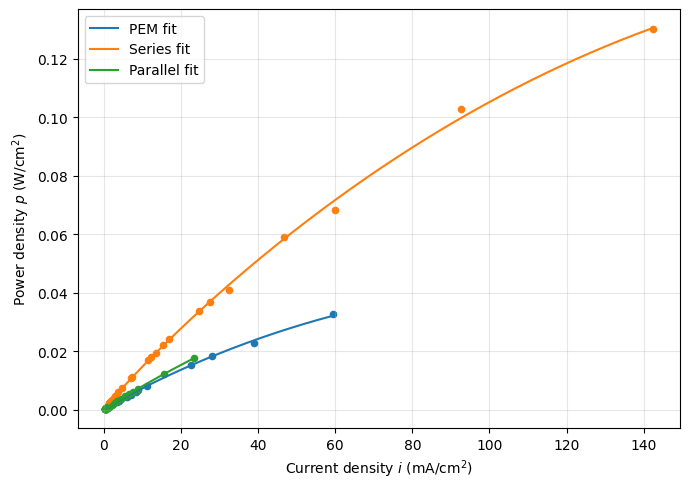

In [ ]:
# Hydrogen multi-panel power-density curves: PEM, series, and parallel
# Power density, eqn [10]: p = V * i
# V [mV] * i [mA/cm^2] = uW/cm^2  ->  x 1e-6  ->  W/cm^2 (handout units)
TO_W = 1e-6

fig, axes = plt.subplots(1, len(datasets), figsize=(6 * len(datasets), 4.8))
for ax, (name, i, V) in zip(axes, datasets):
    p_par, cov = fits[name]
    i_fit = np.linspace(i.min(), i.max(), 400)
    V_fit = model(i_fit, *p_par)                  # eqn [15]
    band = conf_band(i_fit, p_par, cov, len(i))

    p_data = V * i * TO_W                         # eqn [10], measured
    p_fit = V_fit * i_fit * TO_W                  # eqn [10] applied to eqn [15] fit
    p_band = band * i_fit * TO_W                  # i is exact, so the band scales by i

    k = np.argmax(p_fit)
    print(f"{name}: p_max = {p_fit[k]:.3e} W/cm^2 at i = {i_fit[k]:.2f} mA/cm^2, "
          f"V = {V_fit[k]:.0f} mV")

    ax.scatter(i, p_data, color="b", s=20, label="_nolegend_")
    ax.plot(i_fit, p_fit, "r-", label="eqn [10] with eqn [15] fit")
    ax.fill_between(i_fit, p_fit - p_band, p_fit + p_band, color="r", alpha=0.2, label="95% CI")
    ax.plot(i_fit[k], p_fit[k], "k*", ms=12, label="max (fit)")
    ax.set_xlabel(r"Current density $i$ (mA/cm$^2$)")
    ax.set_ylabel(r"Power density $p$ (W/cm$^2$)")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

# Overlay of all three configurations
fig, ax = plt.subplots(figsize=(7, 5))
for (name, i, V), color in zip(datasets, ["tab:blue", "tab:orange", "tab:green"]):
    p_par, _ = fits[name]
    i_fit = np.linspace(i.min(), i.max(), 400)
    ax.scatter(i, V * i * TO_W, s=20, color=color, label="_nolegend_")
    ax.plot(i_fit, model(i_fit, *p_par) * i_fit * TO_W, color=color, label=f"{name} fit")
ax.set_xlabel(r"Current density $i$ (mA/cm$^2$)")
ax.set_ylabel(r"Power density $p$ (W/cm$^2$)")
ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Ethanol fuel cell — live Google Sheet `Et-Fuel cell`

This section uses **the same Google Colab authorization, `AREA`, equation [15] model, and power-density units** as the hydrogen section above. Run the hydrogen cells first, then run these cells.

**Default Day 2 comparison:** `5v%`, `10v%`, `13v%`, `2inseries 10v%`, and `2inparallel 10v%` (each listed in the actual Google Sheet). These have **voltage in column A (V)**, **current in column B (mA)**, and header rows that vary by tab. The loader automatically skips nonnumeric header rows and sorts by current density.

**Earlier runs:** `5 v%`, `9.6 v%`, `16.7 v%`, and `5 v% day2` can be enabled below if needed. They were recorded under different conditions and are not included by default. In particular, `5 v% day2` has numerical voltage entries of 82–110 despite a header saying V; the optional configuration explicitly treats those entries as **mV**, which should be verified against the lab notes.

**Data-quality note:** The previously reported 1.95 V series reading was corrected to 1.095 V in the updated source; verify that correction in the live Sheet. Also, `5v%` contains a **0.646 V** reading (with 3.48 mA) that differ from the neighboring trend. The source measurements remain **unchanged** in all plots and fits. Check the source measurements before interpreting fitted parameters or peaks. We do not automatically delete any data.
**Meter-range clarification (parallel run):** `2inparallel 10v%` used the 2 V voltage range and 200 mA current range; the other ethanol runs reportedly used 200 mV and 20 mA ranges. These are **instrument range settings, not unit-conversion factors**. The spreadsheet labels give voltage in V and current in mA for *all* runs, so we convert V → mV by multiplying by 1000 and retain current in mA for all runs. No extra factor of 10 is applied to the parallel experiment. If any values were copied as raw meter display digits rather than the labeled physical units, verify against the original instrument notes before fitting. Some earlier reported voltages exceed 200 mV, so the older range settings deserve verification.

**Normalization:** The parallel two-cell system uses a combined 2 cm² membrane area for current density and power density; all other configurations retain the original 1 cm² reference area (including series, for per-cell-area stack comparison). For the parallel condition, a residual-bootstrap percentile 95% confidence band replaces the unstable local-covariance band. Bootstrap intervals are approximate and rely on Equation [15] and residual-resampling assumptions.


**New mixed-cell conditions:** `H&Et-series` (1 cm² per-cell current-density reference) and `H&Et-parallel` (2 cm² total active membrane area). Both worksheet columns report voltage in V and current in mA. The parallel mixed-cell fit uses the same residual-bootstrap 95% confidence band as the ethanol-only parallel condition. These are mixed hydrogen–ethanol configurations, not additional ethanol-concentration measurements.


In [ ]:
# The Google Sheet is named "Et-Fuel cell" in Drive, NOT "Et-Fuel cell(4).xlsx".
# Reuse gc (the authenticated gspread client) from the hydrogen section.
ethanol_book = gc.open("Et-Fuel cell")

# (plot label, exact worksheet/tab name, voltage conversion factor to mV)
# Meter setting: parallel run = 2 V / 200 mA; other runs reportedly = 200 mV / 20 mA.
# These are *measurement ranges*, not data multipliers. Since the columns
# are labeled V and mA for all tabs, voltage_to_mV = 1000 for every run.
# Do NOT multiply the parallel voltage or current by 10 based on the range.
ETHANOL_CONFIGS = [
    ("5 vol%", "5v%", 1000.0),
    ("10 vol%", "10v%", 1000.0),
    ("13 vol%", "13v%", 1000.0),
    ("Series (10 vol%)", "2inseries: 10v%", 1000.0),
    ("Parallel (10 vol%)", "2inparallel: 10v%", 1000.0),
    ("H+Et series", "H&Et-series", 1000.0),
    ("H+Et parallel", "H&Et-parallel", 1000.0),
]

# Set to True to include EARLIER runs in the same graphs (different run protocol).
INCLUDE_EARLIER_RUNS = False
if INCLUDE_EARLIER_RUNS:
    ETHANOL_CONFIGS += [
        ("5 vol% (earlier)", "5 v%", 1000.0),
        ("9.6 vol% (earlier)", "9.6 v%", 1000.0),
        ("16.7 vol% (earlier)", "16.7 v%", 1000.0),
        # Confirm the voltage unit in the original lab notes before using this tab:
        # ("5 vol% (day2 alternate)", "5 v% day2", 1.0),
    ]

def load_ethanol_sheet(tab, voltage_to_mV=1000.0, active_area=1.0):
    rows = ethanol_book.worksheet(tab).get_all_values()
    measured = []
    for row_number, r in enumerate(rows, start=1):
        # EtOH workbook: A = voltage, B = current (unlike hydrogen B/C).
        if len(r) < 2:
            continue
        try:
            v = float(str(r[0]).strip())
            current = float(str(r[1]).strip())
        except (ValueError, TypeError):
            continue  # skip titles, column headings, empty rows
        if np.isfinite(v) and np.isfinite(current) and current > 0 and v >= 0:
            measured.append((current / active_area, v * voltage_to_mV))

    if len(measured) < 6:
        raise ValueError(f"'{tab}' has only {len(measured)} valid data rows; check its columns and units.")
    data = np.asarray(measured, dtype=float)
    order = np.argsort(data[:, 0], kind="stable")
    return data[order, 0], data[order, 1]  # i [mA/cm²], V [mV]

# Area convention: each membrane is 1 cm². Parallel configurations use
# total active area (2 cm²); series configurations use one-cell reference area.
# This applies to both ethanol-only and mixed hydrogen–ethanol pairings.
AREA_BY_CONDITION = {
    "Parallel (10 vol%)": 2.0,
    "H+Et parallel": 2.0,
}
def condition_area(name):
    return AREA_BY_CONDITION.get(name, 1.0)

ethanol_datasets = []
for name, tab, conversion in ETHANOL_CONFIGS:
    i, V = load_ethanol_sheet(tab, conversion, active_area=condition_area(name))
    ethanol_datasets.append((name, i, V))
    print(f"{name}: {len(i)} points | i: {i.min():.2f}–{i.max():.2f} mA/cm² | "
          f"V: {V.min():.1f}–{V.max():.1f} mV")
print("All recorded points have been retained (no outlier removal).")
print("Meter ranges: parallel = 2 V / 200 mA; others reported = 200 mV / 20 mA.")
print("All columns interpreted as voltage in V and current in mA; ranges do not create a ×10 correction.")

print("Normalization: 2 cm² for both parallel conditions; 1 cm² reference area for single-cell and series conditions.")


5 vol%: 39 points | i: 0.46–8.20 mA/cm² | V: 104.0–718.0 mV
10 vol%: 40 points | i: 0.47–8.95 mA/cm² | V: 113.0–732.0 mV
13 vol%: 42 points | i: 0.45–9.56 mA/cm² | V: 117.0–762.0 mV
Series (10 vol%): 46 points | i: 0.88–11.48 mA/cm² | V: 152.0–1327.0 mV
Parallel (10 vol%): 38 points | i: 0.05–13.35 mA/cm² | V: 54.0–763.0 mV
H+Et series: 27 points | i: 0.95–47.90 mA/cm² | V: 9.0–2000.0 mV
H+Et parallel: 25 points | i: 0.28–16.00 mA/cm² | V: 391.0–869.0 mV
All recorded points have been retained (no outlier removal).
Meter ranges: parallel = 2 V / 200 mA; others reported = 200 mV / 20 mA.
All columns interpreted as voltage in V and current in mA; ranges do not create a ×10 correction.
Normalization: 2 cm² for both parallel conditions; 1 cm² reference area for single-cell and series conditions.


### Ethanol parameter fitting — equation [15]

The same five-parameter function `model(i, C, B, R, w, z)` is used. For ethanol, the existing hydrogen `full_fit` function can fail when its initial guesses fall outside its bounds, so this section uses **multiple valid starting guesses** and keeps the least-squares fit with the smallest residual error. The raw data are never adjusted.

Approximate 95% confidence bands are attempted whenever the covariance matrix is finite, regardless of R²; interpret the bands cautiously when fit parameters are poorly identifiable. **Fitted peak power is a model-based estimate within the measured current range**, not an extrapolation or an independently measured maximum.

### ✏️ MODIFIED — ethanol 5-parameter fit (E fixed, A fitted)

This is the same unconstrained fit as before, except that A is fitted in place of C, with E fixed at the low end of each condition's prelab range. The curve is identical to the old fit; A is just the old C minus E.

In [ ]:
# Equation [15] is defined above as model(i, E, A, B, R, w, z).
# >>> MODIFIED (E/A split): E is fixed from the prelab; A replaces C as the fitted offset.

def ethanol_full_fit(i, V, E):
    linear_guess, _ = linear_scale_fit(i, V)                    # linear_guess[0] = E + A
    f = lambda i, A, B, R, w, z: model(i, E, A, B, R, w, z)
    lower = np.array([-E, 0, 0, 0, 0], dtype=float)             # same limits as before: 0 <= E + A <= 5000
    upper = np.array([5000 - E, 1000, 200, 1000, 1.0], dtype=float)
    first_guess = np.array([
        max(linear_guess[0], V.max()) - E, max(linear_guess[1], 0.01),
        max(linear_guess[2], 0.01), 1.0, 0.03
    ], dtype=float)
    # Ensure each initial guess strictly satisfies the bounds.
    first_guess = np.clip(first_guess, lower + 1e-7, upper - 1e-7)
    guesses = [
        first_guess,
        [V.max() - E, 20, 5, 0.5, 0.1],
        [min(V.max() * 1.15, 4999) - E, 30, 1, 5, 0.05],
        [V.max() - E, 75, 10, 2, 0.15],
    ]

    best = None
    for initial in guesses:
        try:
            p, cov = curve_fit(f, i, V, p0=initial,
                               bounds=(lower, upper), maxfev=60000)
            sse = float(np.sum((V - f(i, *p)) ** 2))
            if best is None or sse < best[0]:
                best = (sse, p, cov)
        except (RuntimeError, ValueError, FloatingPointError):
            continue
    if best is None:
        raise RuntimeError("No five-parameter ethanol fit converged.")
    sse, p, cov = best
    p, cov = with_fixed_E(p, cov, E)                            # back to all 6 parameters
    denominator = np.sum((V - V.mean()) ** 2)
    r2 = 1 - sse / denominator if denominator > 0 else np.nan
    return p, cov, r2

ethanol_fits = {}
for name, i, V in ethanol_datasets:
    p, cov, r2 = ethanol_full_fit(i, V, E_fit(name))
    # A poor fit, ill-defined parameter errors, or boundary estimates
    # makes the usual local-linearized confidence band hard to interpret.
    sds = np.sqrt(np.maximum(np.diag(cov), 0))
    stable = bool(np.isfinite(cov).all() and np.isfinite(sds).all())
    ethanol_fits[name] = (p, cov, r2, stable)
    print(f"--- {name} (R² = {r2:.4f}; 95% CI {'shown' if stable else 'not shown'})")
    for param, value, sd in zip(["E", "A", "B", "R", "w", "z"], p, sds):
        if param == "E":
            print(f"  E = {value:.6g} (fixed, low end of prelab range)")
        else:
            print(f"  {param} = {value:.4g} ± {sd:.2g}")
    if not stable:
        print("  NOTE: weak or unstable fit; interpret estimated parameters cautiously.")

--- 5 vol% (R² = 0.9386; 95% CI shown)
  E = 1166.33 (fixed, low end of prelab range)
  A = -436.8 ± 8.1e+02
  B = 178.7 ± 1.4e+02
  R = 1.056e-12 ± 2.2e+02
  w = 70.72 ± 8.8e+02
  z = 0.2318 ± 0.88
--- 10 vol% (R² = 0.9980; 95% CI shown)
  E = 1166.33 (fixed, low end of prelab range)
  A = -475.7 ± 4.4
  B = 173.7 ± 12
  R = 21.86 ± 3.6
  w = 0.02775 ± 0.053
  z = 1 ± 0.21
--- 13 vol% (R² = 0.9863; 95% CI shown)
  E = 1166.33 (fixed, low end of prelab range)
  A = -516 ± 14
  B = 208.7 ± 35
  R = 30.92 ± 12
  w = 0.002331 ± 0.31
  z = 1 ± 14
--- Series (10 vol%) (R² = 0.9985; 95% CI shown)
  E = 2332.66 (fixed, low end of prelab range)
  A = -965.3 ± 3.3
  B = 156.3 ± 20
  R = 50.53 ± 3.4
  w = 0.004674 ± 0.0048
  z = 1 ± 0.088
--- Parallel (10 vol%) (R² = 0.9978; 95% CI shown)
  E = 1166.33 (fixed, low end of prelab range)
  A = -400.9 ± 3.7
  B = 2.923 ± 4.8
  R = 42.03 ± 2.9
  w = 0.0002342 ± 0.056
  z = 1 ± 18
--- H+Et series (R² = 0.9257; 95% CI shown)
  E = 2395.33 (fixed, low e

### 🆕 ADDED — Ethanol: constrained fits

Each condition's constraint and the reason for it is listed in `ETHANOL_CONSTRAINTS`. The conditions where $w$ is set to 0 follow the professor's rule directly.

**Exceptions (not set to zero):**
- **10 vol%:** w failed the rule, but removing it makes the fit miss the high-current drop (the F-test says the term is needed). Raising the z cap didn't work either, because z then fits only the last point. Instead, z is fixed at the series-cell value (1.664). The series cell runs the same 10 vol% fuel with the same current density through each cell, so its mass-transport exponent should be the same.
- **Series (10 vol%):** w failed the rule only barely, and the high-current drop is clearly in the data (F-test p ≪ 0.05). The real problem was z stuck at the old cap of 1. With the cap raised to 5, z settles at ≈1.66 and every parameter is well determined. Nothing is fixed.

- **Parallel (10 vol%):** like 10 vol%, the high-current drop is real (F-test p ≪ 0.05), so z is fixed at the series-cell value instead of removing w. B was then set to 0 because its error was larger than its value: the curve is nearly flat at low current and shows no clear activation region, so this run can't resolve the Tafel slope (and i₀ can't be calculated). A then acts only as a constant offset.

E is fixed from the prelab for every condition (see the E table near the top); A is reported at both ends of the E range.

**The confidence bands and plots below now use these constrained fits.**

In [ ]:
# ===================== ADDED: ethanol constrained fits =====================
# (constraint, reason) for each condition. E is added automatically from E_RANGE.
ETHANOL_CONSTRAINTS = {
    "5 vol%": ({"w": 0.0, "z": 0.0},
               "A, R, w, z had error > value; removing w lets A and R be determined."),
    "10 vol%": ({"z": 1.664},
                "NOT set to zero: the high-current drop is real (F-test), so z is fixed at the "
                "series-cell value (same 10 vol% fuel, same current density per cell)."),
    "13 vol%": ({"w": 0.0, "z": 0.0},
                "w and z had error > value; no mass-transport drop in the data."),
    "Series (10 vol%)": ({},
                         "NOT set to zero: the high-current drop is real (F-test). Only the z cap "
                         "was raised from 1 to 5."),
    "Parallel (10 vol%)": ({"B": 0.0, "z": 1.664},
                         "z fixed at the series-cell value (high-current drop is real, F-test). "
                         "B set to 0: error > value, and the curve shows no low-current activation region."),
    "H+Et series": ({"w": 0.0, "z": 0.0},
                    "z ≈ 0, so w·e^(zi) ≈ w duplicated A; A, R, w, z had error > value."),
    "H+Et parallel": ({"w": 0.0, "z": 0.0},
                      "z ≈ 0, so w·e^(zi) ≈ w duplicated A; A, R, w, z had error > value."),
}

ETHANOL_FIXED = {}   # used by the confidence-band cell below (includes E)
for name, i, V in ethanol_datasets:
    fixed, note = ETHANOL_CONSTRAINTS.get(name, ({}, "no constraint listed for this condition"))
    _, _, r2_original = ethanol_full_fit(i, V, E_fit(name))    # original fit, for comparison
    sse_original = (1 - r2_original) * np.sum((V - V.mean()) ** 2)
    p, cov, r2, fixed_all = run_constrained(name, i, V, fixed, sse_original, r2_original, note)
    ETHANOL_FIXED[name] = fixed_all
    ethanol_fits[name] = (p, cov, r2, bool(np.isfinite(cov).all()))   # plots below use this fit


--- 5 vol%: R² = 0.9386 (all free)  ->  0.9280 (constrained)
  fixed: w = 0, z = 0
  E = 1166.33 to 1421 mV (fixed, prelab range)  ->  A = -455 to -709.7 ± 12 mV
  i0 = 10^(A/B) = 1.3e-08 to 5.1e-13 mA/cm²
  B = 57.73 ± 42
  R = 64.34 ± 8.5
  F-test for the w·e^(zi) term: F = 2.95, p = 0.0661  (term not needed)
  note: A, R, w, z had error > value; removing w lets A and R be determined.
--- 10 vol%: R² = 0.9980 (all free)  ->  0.9991 (constrained)
  fixed: z = 1.664
  E = 1166.33 to 1421 mV (fixed, prelab range)  ->  A = -470.7 to -725.3 ± 1.7 mV
  i0 = 10^(A/B) = 0.0012 to 3.3e-05 mA/cm²
  B = 161.8 ± 5.4
  R = 26.17 ± 1.2
  w = 6.6e-05 ± 2.1e-06
  F-test for the w·e^(zi) term: F = 220.47, p = 1.46e-20  (term needed)
  note: NOT set to zero: the high-current drop is real (F-test), so z is fixed at the series-cell value (same 10 vol% fuel, same current density per cell).
--- 13 vol%: R² = 0.9863 (all free)  ->  0.9859 (constrained)
  fixed: w = 0, z = 0
  E = 1166.33 to 1421 mV (fixed,

### ✏️ MODIFIED — confidence-band cell

The bootstrap for the parallel conditions now refits with the **same constraints** as above. Before, it refit all 5 parameters with z capped at 1, which would have undone the constraints. The changed lines are marked `# >>> MODIFIED`.

In [ ]:
# 95% confidence bands for ethanol performance curves.
# Parallel cells use a residual-bootstrap percentile interval to avoid the
# numerically explosive local covariance estimate of the five-parameter fit.
# This interval describes uncertainty in the fitted mean curve conditional
# on the fitted model and the residual-resampling assumptions.
from scipy.optimize import curve_fit

PARALLEL_LABELS = {"Parallel (10 vol%)", "H+Et parallel"}
BOOTSTRAP_REPS = 250
BOOTSTRAP_SEED = 4100


def ethanol_plot_interval(name, i_fit, i, V, params, cov, n_boot=BOOTSTRAP_REPS):
    if name not in PARALLEL_LABELS:
        if not np.isfinite(cov).all():
            return None
        try:
            halfwidth = conf_band(i_fit, params, cov, len(i))
            if np.isfinite(halfwidth).all():
                center = model(i_fit, *params)
                return center - halfwidth, center + halfwidth
        except (ValueError, FloatingPointError, OverflowError):
            pass
        return None

    # Bootstrap: re-fit Equation [15] at each resample, with the same constraints.
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    residuals = V - model(i, *params)
    residuals = residuals - np.mean(residuals)
    expected = model(i, *params)
    fixed = ETHANOL_FIXED.get(name, {"E": E_fit(name)})   # >>> MODIFIED: same constraints (incl. E) as the fit
    predictions = []
    for _ in range(n_boot):
        V_resampled = expected + rng.choice(residuals, size=len(residuals), replace=True)
        try:
            p_boot, _, _ = constrained_fit(i, V_resampled, fixed)   # >>> MODIFIED: constrained refit
            pred = model(i_fit, *p_boot)
            if np.isfinite(pred).all():
                predictions.append(pred)
        except (RuntimeError, ValueError, FloatingPointError, OverflowError):
            continue

    print(f"{name}: {len(predictions)}/{n_boot} bootstrap refits converged")
    if len(predictions) < max(50, int(n_boot * 0.7)):
        print("Bootstrap fit success too low for a reliable displayed 95% interval.")
        return None
    samples = np.asarray(predictions)
    return np.percentile(samples, 2.5, axis=0), np.percentile(samples, 97.5, axis=0)

# Calculate each band once and use the same interval for voltage and power.
ethanol_intervals = {}
for name, i, V in ethanol_datasets:
    p, cov, r2, stable = ethanol_fits[name]
    i_fit = np.linspace(i.min(), i.max(), 400)
    ethanol_intervals[name] = ethanol_plot_interval(name, i_fit, i, V, p, cov)


Parallel (10 vol%): 250/250 bootstrap refits converged
H+Et parallel: 250/250 bootstrap refits converged


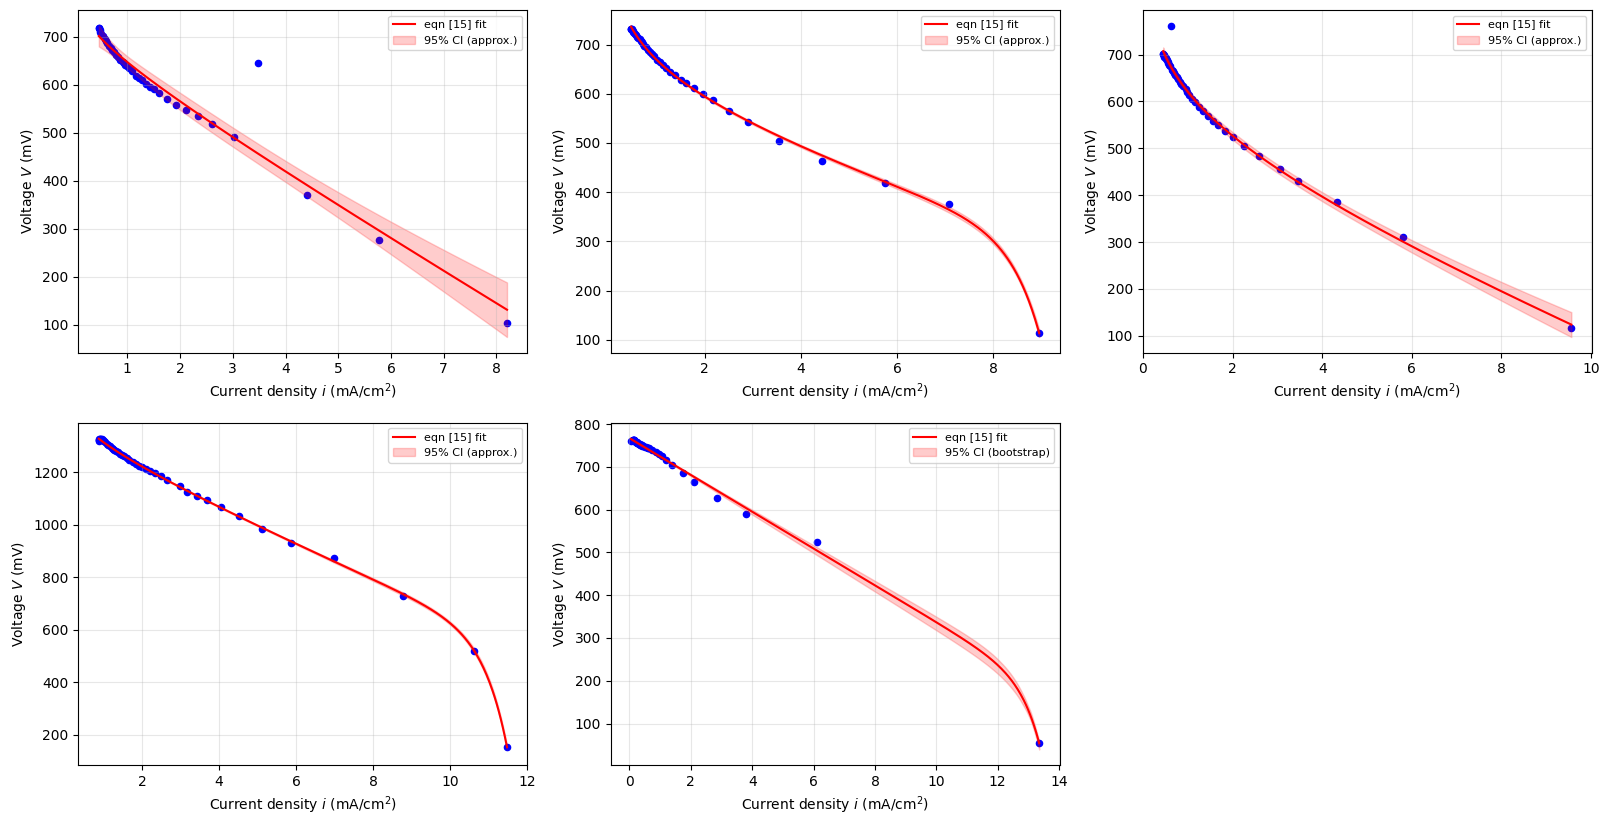

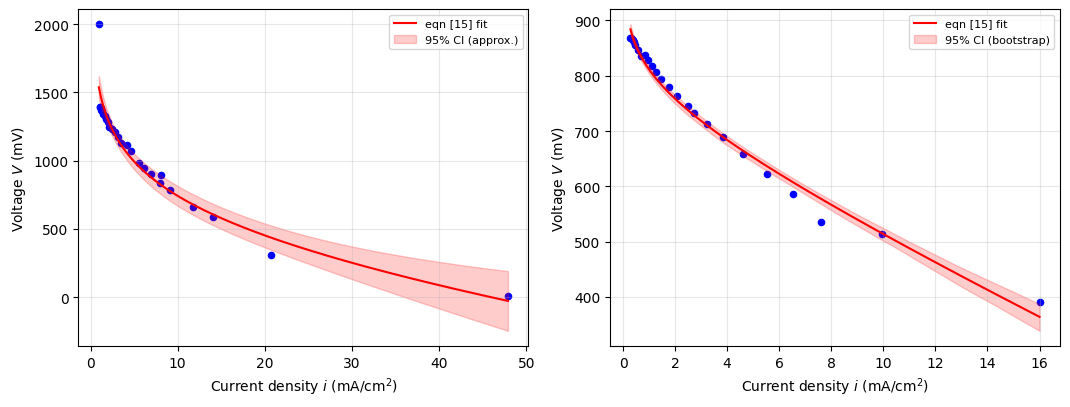

In [ ]:
# Separate ethanol-only and mixed-fuel performance curves.
# Define the plot groups once and reuse them for polarization and power-density plots.
ETHANOL_ONLY_LABELS = [
    "5 vol%", "10 vol%", "13 vol%",
    "Series (10 vol%)", "Parallel (10 vol%)",
]
MIXED_LABELS = ["H+Et series", "H+Et parallel"]

ethanol_data_by_name = {name: (i, V) for name, i, V in ethanol_datasets}

def plot_performance_panels(labels, title, ncols):
    nrows = (len(labels) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.4 * ncols, 4.4 * nrows), squeeze=False)
    for ax, name in zip(axes.flat, labels):
        i, V = ethanol_data_by_name[name]
        p, cov, r2, stable = ethanol_fits[name]
        i_fit = np.linspace(i.min(), i.max(), 400)
        V_fit = model(i_fit, *p)
        ax.scatter(i, V, s=20, color="b", label="_nolegend_")
        ax.plot(i_fit, V_fit, "r-", label="eqn [15] fit")
        interval = ethanol_intervals[name]
        if interval is not None:
            lo, hi = interval
            ci_label = "95% CI (bootstrap)" if name in PARALLEL_LABELS else "95% CI (approx.)"
            ax.fill_between(i_fit, lo, hi, color="r", alpha=0.2, label=ci_label)
        else:
            print(f"{name}: 95% CI unavailable from this fit; no interval fabricated.")
        ax.set_xlabel(r"Current density $i$ (mA/cm$^2$)")
        ax.set_ylabel(r"Voltage $V$ (mV)")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
    for ax in list(axes.flat)[len(labels):]:
        ax.set_visible(False)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

plot_performance_panels(
    ETHANOL_ONLY_LABELS,
    "Ethanol performance curves: concentration and configuration",
    ncols=3,
)
plot_performance_panels(
    MIXED_LABELS,
    "Mixed fuel cells performance curves: series and parallel",
    ncols=2,
)


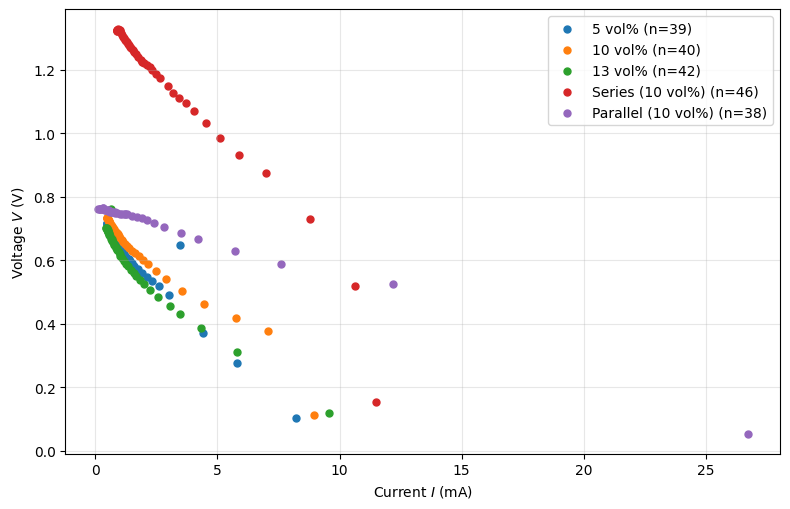

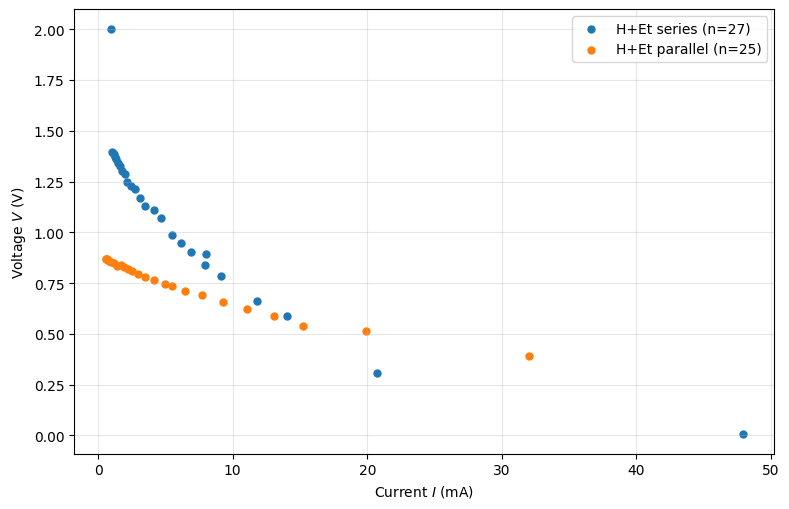

In [ ]:
# Keep ethanol and mixed-fuel polarization curves on separate comparison plots.
# The source V values are in mV, and i is in mA/cm²; convert to V and mA.

def plot_polarization_overlay(labels, title):
    fig, ax = plt.subplots(figsize=(8, 5.2))
    for name in labels:
        i, V = ethanol_data_by_name[name]
        ax.scatter(i * condition_area(name), V / 1000.0, s=25,
                   label=f"{name} (n={len(i)})")
    ax.set_xlabel(r"Current $I$ (mA)")
    ax.set_ylabel(r"Voltage $V$ (V)")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_polarization_overlay(
    ETHANOL_ONLY_LABELS,
    "Ethanol polarization curves: concentration and configuration",
)
plot_polarization_overlay(
    MIXED_LABELS,
    "Mixed fuel cells polarization curves: series and parallel",
)


### Power-density plotting helpers

The plotted values use the original measured data and fitted model parameters. No new fitting is performed here.

In [ ]:
# Power density, equation [10]: p = V * i
# With V in mV and i in mA/cm², multiply by 1e-6 to obtain W/cm².
# Uses the model fits and the precomputed 95% confidence intervals above.

# Reuse the existing measured data and model fits; do not re-fit or alter data.
ethanol_data_by_name = {name: (i, V) for name, i, V in ethanol_datasets}

def plot_power_density_panels(labels, title, ncols):
    nrows = (len(labels) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.3 * ncols, 4.4 * nrows), squeeze=False)

    for ax, name in zip(axes.flat, labels):
        i, V = ethanol_data_by_name[name]
        params, cov, r2, stable = ethanol_fits[name]
        i_fit = np.linspace(i.min(), i.max(), 400)
        V_fit = model(i_fit, *params)
        p_data = V * i * 1e-6
        p_fit = V_fit * i_fit * 1e-6
        k_fit = int(np.argmax(p_fit))
        k_observed = int(np.argmax(p_data))
        print(f"{name}: measured max = {p_data[k_observed]:.3e} W/cm² "
              f"at i = {i[k_observed]:.2f} mA/cm²; "
              f"fitted max = {p_fit[k_fit]:.3e} W/cm² "
              f"at i = {i_fit[k_fit]:.2f} mA/cm²")

        ax.scatter(i, p_data, color="b", s=20, label="_nolegend_")
        ax.plot(i_fit, p_fit, "r-", label="eqn [10] with eqn [15] fit")
        interval = ethanol_intervals[name]
        if interval is not None:
            lo, hi = interval
            ci_label = "95% CI (bootstrap)" if name in PARALLEL_LABELS else "95% CI (approx.)"
            ax.fill_between(i_fit, lo * i_fit * 1e-6, hi * i_fit * 1e-6,
                            color="r", alpha=0.2, label=ci_label)
        ax.plot(i_fit[k_fit], p_fit[k_fit], "k*", ms=12, label="max (fit)")
        ax.set_xlabel(r"Current density $i$ (mA/cm$^2$)")
        ax.set_ylabel(r"Power density $p$ (W/cm$^2$)")
        ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)

    for ax in list(axes.flat)[len(labels):]:
        ax.set_visible(False)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


def plot_power_density_overlay(labels, title):
    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    for name in labels:
        i, V = ethanol_data_by_name[name]
        params, _, r2, _ = ethanol_fits[name]
        i_fit = np.linspace(i.min(), i.max(), 400)
        line, = ax.plot(i_fit, model(i_fit, *params) * i_fit * 1e-6,
                        label=f"{name} fit (R²={r2:.3f})")
        ax.scatter(i, V * i * 1e-6, s=20, color=line.get_color())
    ax.set_xlabel(r"Current density $i$ (mA/cm$^2$)")
    ax.set_ylabel(r"Power density $p$ (W/cm$^2$)")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


### Ethanol: five power-density panels

5, 10, and 13 vol% ethanol, plus series and parallel configurations at 10 vol%.

5 vol%: measured max = 2.248e-03 W/cm² at i = 3.48 mA/cm²; fitted max = 1.747e-03 W/cm² at i = 5.02 mA/cm²
10 vol%: measured max = 2.665e-03 W/cm² at i = 7.07 mA/cm²; fitted max = 2.578e-03 W/cm² at i = 7.10 mA/cm²
13 vol%: measured max = 1.804e-03 W/cm² at i = 5.80 mA/cm²; fitted max = 1.747e-03 W/cm² at i = 5.91 mA/cm²
Series (10 vol%): measured max = 6.401e-03 W/cm² at i = 8.78 mA/cm²; fitted max = 6.479e-03 W/cm² at i = 9.06 mA/cm²
Parallel (10 vol%): measured max = 3.196e-03 W/cm² at i = 6.10 mA/cm²; fitted max = 3.422e-03 W/cm² at i = 8.92 mA/cm²


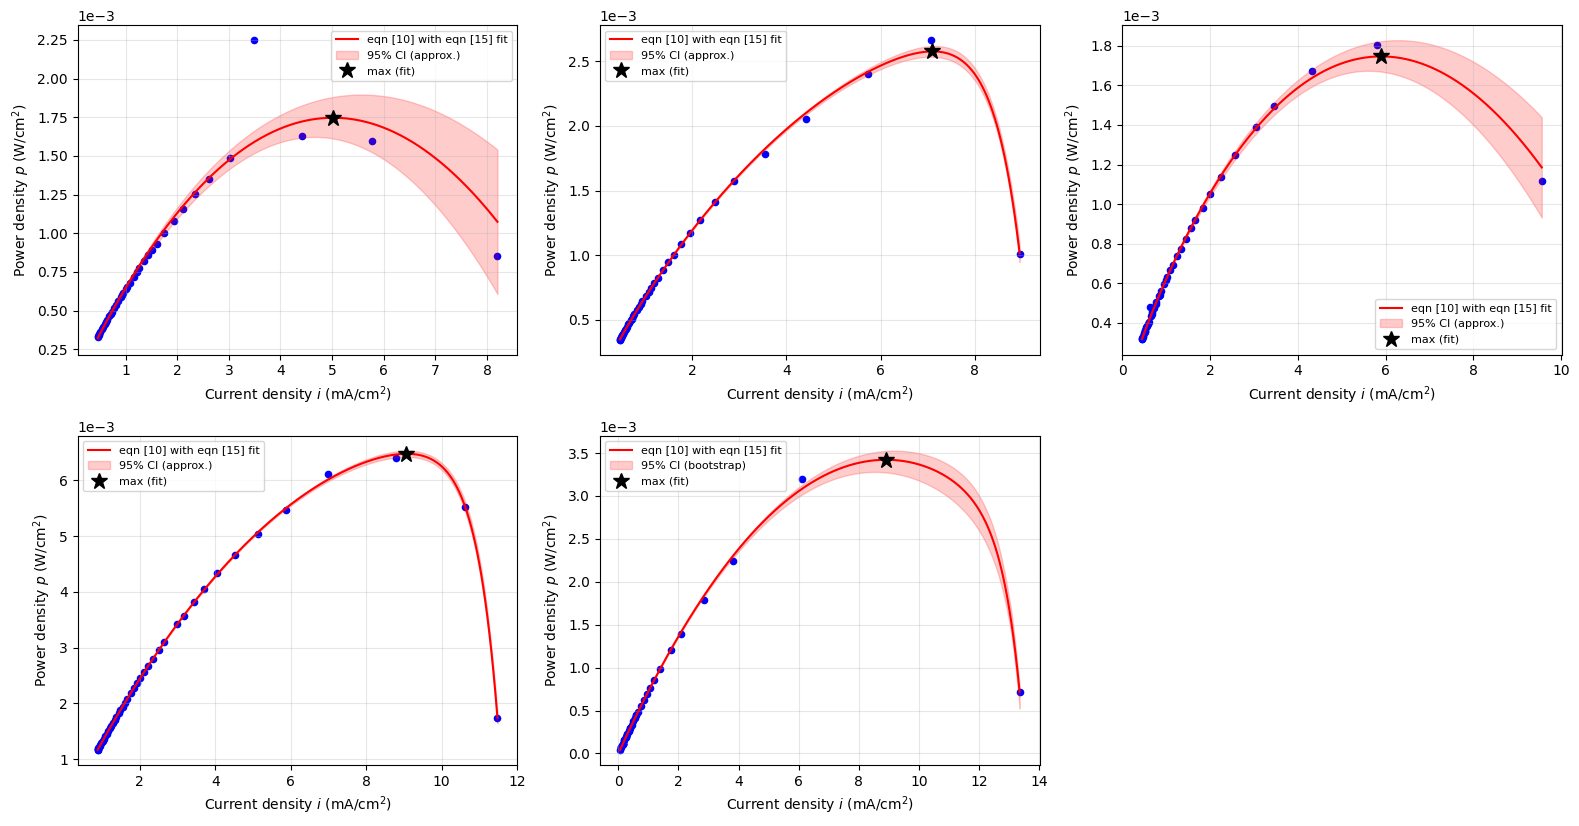

In [ ]:
plot_power_density_panels(
    ETHANOL_ONLY_LABELS,
    "Ethanol power-density curves: concentration and cell configuration",
    ncols=3,
)

### Ethanol: concentration and configuration comparison

This overlay **excludes** H+Et series and H+Et parallel.

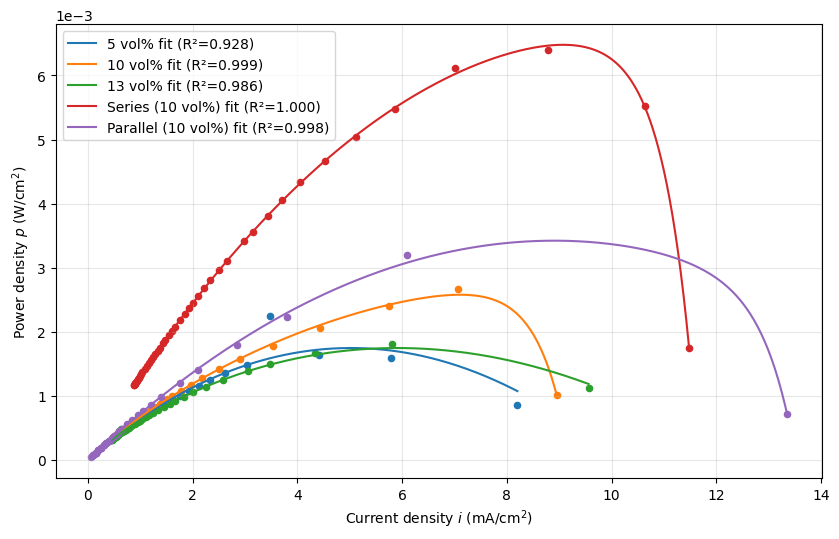

In [ ]:
plot_power_density_overlay(
    ETHANOL_ONLY_LABELS,
    "Ethanol power density: concentration and cell configuration",
)

### Mixed fuel cells: two power-density panels

H+Et series and H+Et parallel only.

H+Et series: measured max = 8.218e-03 W/cm² at i = 14.00 mA/cm²; fitted max = 9.034e-03 W/cm² at i = 19.78 mA/cm²
H+Et parallel: measured max = 6.256e-03 W/cm² at i = 16.00 mA/cm²; fitted max = 5.831e-03 W/cm² at i = 15.49 mA/cm²


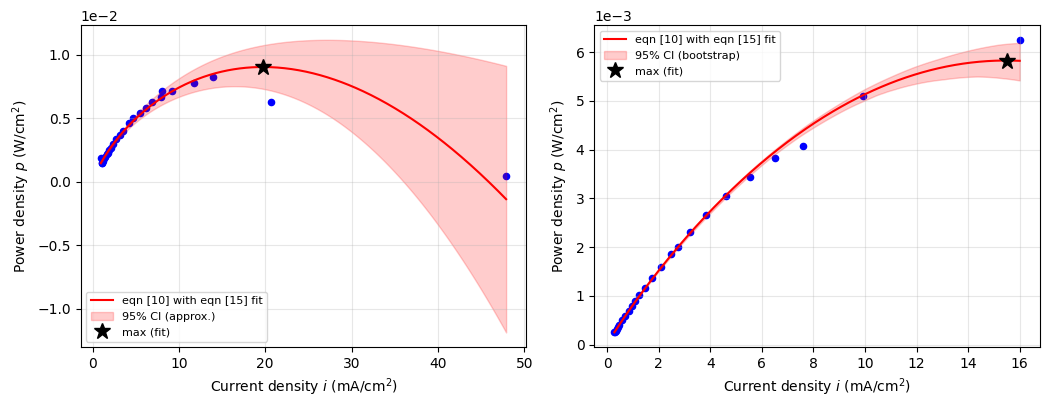

In [ ]:
plot_power_density_panels(
    MIXED_LABELS,
    "Mixed fuel cells power-density curves: series and parallel",
    ncols=2,
)

### Mixed fuel cells: configuration comparison

This overlay **only** includes H+Et series and H+Et parallel.

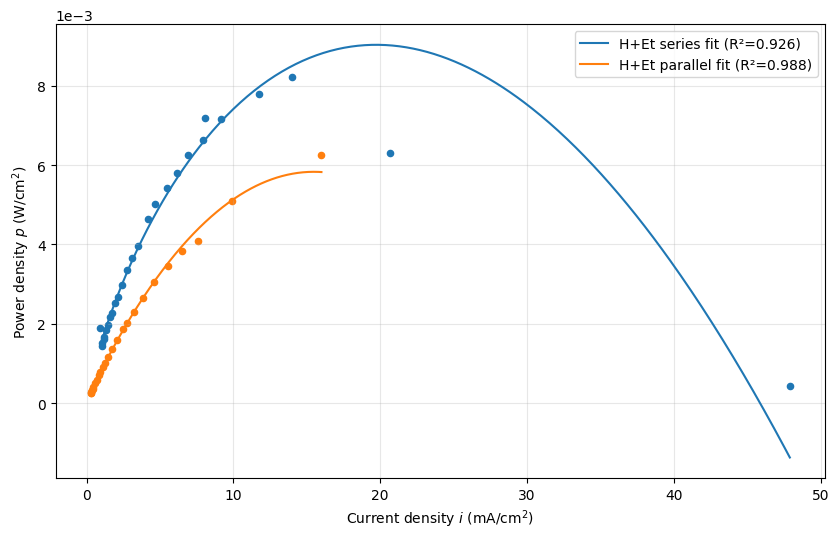

In [ ]:
plot_power_density_overlay(
    MIXED_LABELS,
    "Mixed fuel cells power density: concentration and cell configuration",
)